# KITScenes — SD maps and navigation

Every download has OpenStreetMap snapshots of the three cities (`openstreetmap_sd_maps/`): the road network as a
navigation system knows it, without lanes. `kitscenes.sdmap` reads them into a road graph in the frame of the
scene's poses, matches the drive to it and routes on it; `kitscenes.navigation` turns a route into driving commands.
This notebook shows the SD map around a frame, the driven route with its maneuvers, the route on the HD map, and the
commands.

Experimental: the benchmark's navigation input is not final; the test-e2e scenes will ship their commands.

**Needs:** `kitscenes[map,viz]` installed as in the README (the HD map is used in section 4 only), and
`kitscenes[sdmap]` for the last cell (networkx; skipped without it). The example scene and how to download it alone:
notebook 01.

**Licence:** the OpenStreetMap files are under the ODbL 1.0, not the dataset licence
(`openstreetmap_sd_maps/ATTRIBUTION.md`): figures and models need the attribution `kitscenes.sdmap.ATTRIBUTION`,
published data derived from the files falls under the ODbL (`docs/sdmap.md`).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works

from kitscenes.map import Circle, Region
from kitscenes.navigation import KITSCENES, NAVSIM, NUSCENES, Command, driving_commands

# lanelet2 notes on the routing graphs of the maps (SceneMap.routing_problems lists them): not shown here
import logging
import warnings

from kitscenes.map import MapProblemWarning

warnings.filterwarnings("ignore", category=MapProblemWarning)
logging.getLogger("kitscenes.map.scene_map").addFilter(lambda record: "routing graph" not in record.getMessage())

In [2]:
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
scene = ds[SCENE_ID]
frame = scene[min(50, len(scene) - 1)]
print(scene.info.city, scene.info.recording_week, "| SD snapshot:", scene.info.sd_snapshot)

Frankfurt 2025-W34 | SD snapshot: Frankfurt_2025-W34.osm.pbf


## 1. The SD map of a scene

`scene.sd_map` is an `SDMap`: the OpenStreetMap state of the scene's recording week, in the map frame of the scene's
poses (2D, OpenStreetMap has no heights). `ds.sd_maps()` lists the snapshots on disk, `ds.sd_map(city)` loads one.
A file is parsed once (5–20 s) and the parsed arrays are cached (`~/.cache/kitscenes`, or `$KITSCENES_CACHE`);
all scenes of a city and week share one `SDMap`. The test-e2e scenes cannot be placed on it: their poses are
relative to their first pose.

In [3]:
smap = scene.sd_map
print(smap.city, "| data state:", smap.snapshot, "|", kitscenes.sdmap.ATTRIBUTION)
for city, snapshots in ds.sd_maps().items():
    print(f"{city:13s}", ", ".join(snapshots))

Frankfurt | data state: 2025-08-18T00:00:00Z | © OpenStreetMap contributors, ODbL 1.0
Frankfurt     2025-W34, paper_2026-05-03
Karlsruhe     2025-W33, 2026-W06, 2026-W12, paper_2026-05-03
Sindelfingen  2026-W08, paper_2026-05-03


## 2. Roads around a frame

Queries take a region as for the HD map (notebook 04). `smap.roads(box)` are the edges of the road graph: an
`SDRoad` is one drivable direction of a road piece between two junctions, with its class, speed limit, lanes and
neighbours, each value with its source (a tag, or a default). `smap.attributes_at(pose)` is the road the vehicle
is on (heading-aware). `smap.elements(box)` gives every OpenStreetMap element in the box with all its tags
(ways, tagged nodes, relations), e.g. as a model input; `.in_ego(pose, road_height_m=scene.road_height_m)` moves
them onto the road below the base frame.

91 roads within 220 m; the vehicle is on 'Gartenstraße' (B 43): primary, 50 km/h (tag), 2 lanes (tag), one-way True


393 ways, 182 tagged nodes, 27 relations, e.g. way 4519609: {'highway': 'primary', 'lanes': '3', 'maxspeed': '50', 'name': 'Gartenstraße', 'oneway': 'yes'}


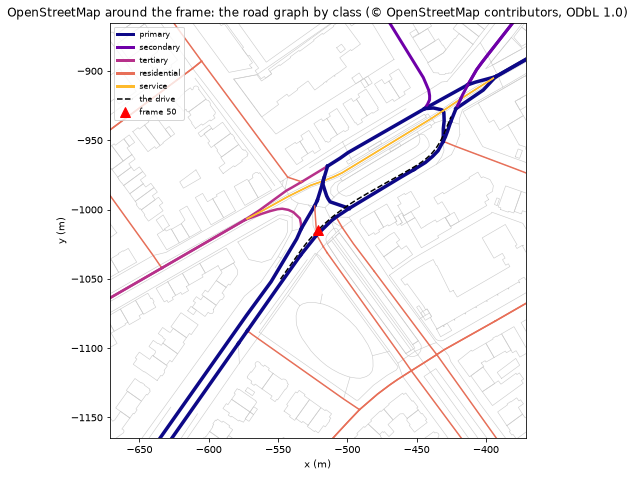

In [4]:
box = Circle.around(frame.pose, 220)  # or a Region(...).around(pose)
roads = smap.roads(box)
here = smap.attributes_at(frame.pose)
print(f"{len(roads)} roads within 220 m; the vehicle is on {here.name!r} ({here.ref}): {here.road_class.value}, "
      f"{here.speed_limit_kph:.0f} km/h ({here.speed_limit_source}), {here.lanes} lanes ({here.lanes_source}), "
      f"one-way {here.one_way}")
elements = smap.elements(box)
print(f"{len(elements.way_ids)} ways, {len(elements.node_ids)} tagged nodes, {len(elements.relations)} relations, "
      f"e.g. way {elements.way_ids[0]}: { {k: v for k, v in elements.way_tags[0].items() if k in ('highway', 'name', 'lanes', 'maxspeed', 'oneway')} }")

WIDTHS = {"motorway": 4, "trunk": 4, "primary": 3.5, "secondary": 3, "tertiary": 2.5}
classes = sorted({road.road_class for road in roads}, key=lambda c: c.rank)
colours = {c: plt.cm.plasma(i / max(len(classes) - 1, 1) * 0.85) for i, c in enumerate(classes)}
drive = scene.track.xyz
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for points in elements.way_points:  # every way: buildings, paths, rails, ...
    ax.plot(points[:, 0], points[:, 1], color="0.8", linewidth=0.6)
for road in roads:
    ax.plot(road.points[:, 0], road.points[:, 1], color=colours[road.road_class],
            linewidth=WIDTHS.get(road.road_class.value, 1.5))
ax.plot(drive[:, 0], drive[:, 1], "k--", linewidth=1.5, label="the drive")
ax.plot(*frame.pose.xyz[:2], "r^", markersize=10, label=f"frame {frame.index}")
handles = [plt.Line2D([], [], color=colours[c], linewidth=3, label=c.value) for c in classes]
ax.legend(handles=handles + ax.get_legend_handles_labels()[0], loc="upper left", fontsize=8)
x, y = frame.pose.xyz[:2]
ax.set(xlim=(x - 150, x + 150), ylim=(y - 150, y + 150), aspect="equal", xlabel="x (m)", ylabel="y (m)",
       title=f"OpenStreetMap around the frame: the road graph by class ({kitscenes.sdmap.ATTRIBUTION})")
plt.show()

## 3. The driven route and its maneuvers

`scene.sd_route` is the route the vehicle drove on the road graph: the poses are map-matched (a hidden Markov
model over the candidates every 5 m), once per scene. An `SDRoute` has the road IDs, a polyline (`points`) and
`maneuvers`: one at every junction the route passes where it had a choice, with the turn angle and a direction.
`route.next_maneuver(pose)` is the next one ahead with the distance to it. `smap.route(start, goal)` plans a route
between two poses (A* with turn restrictions); here it finds the driven one.

In [5]:
route = scene.sd_route
print(f"driven route: {len(route.road_ids)} roads, {route.length_m:.0f} m")
print(f"{'at (m)':>7s}  {'kind':10s} {'direction':13s} {'angle':>6s}  {'exits':>5s}  control")
for m in route.maneuvers:
    print(f"{m.s_m:7.0f}  {m.kind:10s} {m.direction.value:13s} {np.degrees(m.angle_rad):5.0f}°  {m.options:5d}  {m.control}")
ahead, distance = route.next_maneuver(scene[0].pose)
print(f"from frame 0: {ahead.kind} {ahead.direction.value} in {distance:.0f} m")

planned = smap.route(scene[0].pose, scene[len(scene) - 1].pose)
print(f"planned from the first to the last pose: {planned.length_m:.0f} m, the same roads:",
      planned.road_ids == route.road_ids)

driven route: 8 roads, 175 m
 at (m)  kind       direction      angle  exits  control


      0  depart     straight          0°      0  none
     41  turn       slight_right    -20°      2  traffic_signals
    156  continue   straight         19°      3  none
    175  arrive     straight          0°      0  none
from frame 0: turn slight_right in 41 m
planned from the first to the last pose: 175 m, the same roads: True


## 4. The route on the HD map

`route.to_lanelets(scene.map)` gives an HD lane route along the SD route: lanelet IDs for `scene.map.lane(id)`
(notebook 04), or None where the HD map has no such route. It joins the lanes at the route's two ends and may use a
neighbouring lane, so it lies within a few metres of the poses.

24 lanes along the SD route


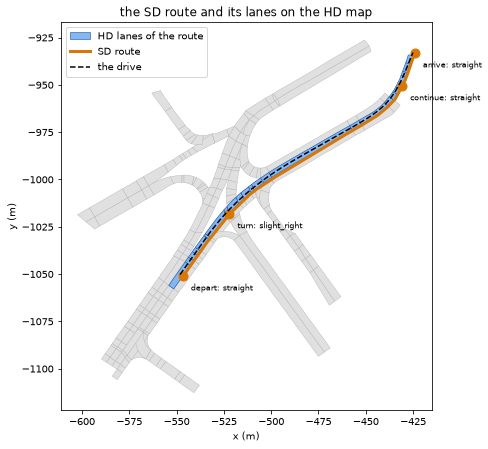

In [6]:
hd = scene.map
lane_ids = route.to_lanelets(hd)
print(None if lane_ids is None else f"{len(lane_ids)} lanes along the SD route")

fig, ax = plt.subplots(figsize=(9, 7))
around = Region(ahead=140, behind=60, left=70, right=70).around(scene[0].pose)
for lane in hd.drivable_lanes(around):
    outline = np.vstack([lane.left_points[:, :2], lane.right_points[::-1, :2]])
    ax.fill(outline[:, 0], outline[:, 1], color="0.88", edgecolor="0.7", linewidth=0.4)
for k, lane_id in enumerate(lane_ids or []):
    lane = hd.lane(lane_id)
    outline = np.vstack([lane.left_points[:, :2], lane.right_points[::-1, :2]])
    ax.fill(outline[:, 0], outline[:, 1], color="#86b6ef", edgecolor="#1c5cab", linewidth=0.6,
            label=None if k else "HD lanes of the route")
ax.plot(route.points[:, 0], route.points[:, 1], "-", color="#d97706", linewidth=3, label="SD route")
for m in route.maneuvers:
    ax.plot(*m.xy, "o", color="#d97706", markersize=9)
    ax.annotate(f"{m.kind}: {m.direction.value}", m.xy, xytext=(8, -14), textcoords="offset points", fontsize=8)
ax.plot(drive[:, 0], drive[:, 1], "k--", linewidth=1.5, label="the drive")
ax.set(aspect="equal", xlabel="x (m)", ylabel="y (m)", title="the SD route and its lanes on the HD map")
ax.autoscale_view()
ax.legend(loc="upper left")
plt.show()

## 5. Driving commands

A driving command is a `Command`: LEFT 0, STRAIGHT 1, RIGHT 2, UNKNOWN 3. A `CommandRule` says how it is computed,
and `driving_commands(scene, rule)` gives one per frame:

- `NAVSIM`: the lateral offset of the path point 20 m ahead, ±2 m;
- `NUSCENES`: the lateral offset of the recorded pose 3 s ahead, ±2 m (it reads the future: a label, not an input);
- `KITSCENES`: the next maneuver of the SD route within 40 m, a turn from 35°; a command only at a junction with a
  choice.

The command is UNKNOWN where the rule cannot tell, e.g. at the end of the scene. Near its end the example scene
follows its road through a bend to the left: by the two offset rules that is LEFT, by `KITSCENES` it is STRAIGHT,
as the route stays on its road there.

NAVSIM     {'LEFT': 46, 'STRAIGHT': 149, 'RIGHT': 0, 'UNKNOWN': 25}
NUSCENES   {'LEFT': 44, 'STRAIGHT': 146, 'RIGHT': 0, 'UNKNOWN': 30}
KITSCENES  {'LEFT': 0, 'STRAIGHT': 197, 'RIGHT': 0, 'UNKNOWN': 23}


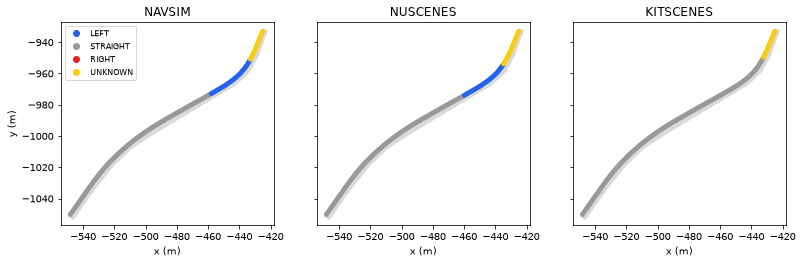

In [7]:
RULES = {"NAVSIM": NAVSIM, "NUSCENES": NUSCENES, "KITSCENES": KITSCENES}
COLOURS = {Command.LEFT: "#2563eb", Command.STRAIGHT: "0.6", Command.RIGHT: "#dc2626", Command.UNKNOWN: "#facc15"}
xy = np.array([f.pose.xyz[:2] for f in scene])  # one position per frame
fig, axes = plt.subplots(1, len(RULES), figsize=(13, 4.6), sharex=True, sharey=True)
for ax, (name, rule) in zip(axes, RULES.items()):
    commands = driving_commands(scene, rule)  # (num_frames,) int8
    print(f"{name:10s}", {c.name: int((commands == c).sum()) for c in Command})
    ax.plot(route.points[:, 0], route.points[:, 1], "-", color="0.85", linewidth=6, zorder=1)
    ax.scatter(xy[:, 0], xy[:, 1], c=[COLOURS[Command(c)] for c in commands], s=14, zorder=2)
    ax.set(aspect="equal", title=name, xlabel="x (m)")
axes[0].set_ylabel("y (m)")
axes[0].legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color=colour, label=c.name)
                        for c, colour in COLOURS.items()], loc="upper left", fontsize=8)
plt.show()

`frame.navigation(rule)` is the navigation input of one frame: the command and, by default, one goal point in the
base frame, the end of the scene's route (the same place for every frame; it does not show the way there).
`targets="route"` gives route points ahead, the route polyline and the next maneuver instead. These follow the
driven route, so they reveal the future path: for analysis, not as a model input for trajectory prediction.
In samples (notebook 05) the same comes with `SampleSpec(navigation=kitscenes.NavigationSpec(rule))`, and the roads
around the frame with `sd_map=kitscenes.SDMapSpec()`.

In [8]:
nav = frame.navigation(KITSCENES)
print(f"command {nav.command.name}, goal point {nav.target_points[0].round(1)} m (x forward, y left; {nav.goal})")
ahead = frame.navigation(KITSCENES, targets="route")
print(f"route points ahead: {ahead.target_points.round(1).tolist()}, next maneuver: {ahead.maneuver.kind} "
      f"{ahead.maneuver.direction.value} in {ahead.distance_to_maneuver_m:.0f} m (negative: inside the junction)")

spec = kitscenes.SampleSpec(sd_map=kitscenes.SDMapSpec(), navigation=kitscenes.NavigationSpec(KITSCENES))
sample = kitscenes.SampleDataset(ds.filter(scene_ids=[SCENE_ID]), spec)[frame.index]
print("sample['navigation']:", {k: (v.shape if hasattr(v, "shape") and v.shape else v) for k, v in sample["navigation"].items()})
print("sample['sd_map']:", {k: (v.shape if hasattr(v, "shape") and v.shape else v) for k, v in sample["sd_map"].items()})

command STRAIGHT, goal point [126.1 -10.2] m (x forward, y left; sd_route)
route points ahead: [[26.9, -4.9], [48.5, -10.1]], next maneuver: turn slight_right in -3 m (negative: inside the junction)
sample['navigation']: {'available': True, 'state': 'present', 'command': np.int64(1), 'target_points': (1, 2), 'target_valid': (1,)}
sample['sd_map']: {'available': True, 'state': 'present', 'xyz': (280, 3), 'length': (14,), 'way_id': (14,), 'road_class': (14,), 'is_link': (14,), 'one_way': (14,), 'lanes': (14,), 'speed_limit_mps': (14,)}


**The graph for your own code.** `smap.to_networkx(box)` gives the road graph as a `networkx.DiGraph`: nodes are
OpenStreetMap node IDs with `xy`, edges are roads with `road_id`, `way_id` and `length_m`.

In [9]:
try:
    graph = smap.to_networkx(box)
    print(graph, "| edge data:", next(iter(graph.edges(data=True)))[2])
except ImportError as err:  # networkx is not installed
    print(err)

DiGraph with 59 nodes and 91 edges | edge data: {'road_id': 814, 'way_id': 4519609, 'length_m': 29.87439502729103}
